In [ ]:
import numpy as np

# 유클리드 거리 함수
def distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


# 클러스터 간 거리는 클러스터 간 평균 거리 계산을 통해 계산함
def cluster_distance(c1, c2, data):
    dist_sum = 0
    count = 0
    for i in c1:
        for j in c2:
            dist_sum += distance(data[i], data[j])
            count += 1
    return dist_sum / count


import numpy as np

x = [
-91.1, -79.2, -88.9, -75.8, -87.4, -12.2, 4.6, -8.1, -33.4, -16.7,
-30.8, -15.5, -34.9, -31.9, 80.1, 82.7, 40.7, 48.9, 75.3, 86.1,
70.1, 65.2, 76.8, 77.9, 61.9, 69.3, -19.3, -2.5, -7, -91.9,
-89.6, -65.4, -76.6, -78.1
]

y = [
-91.9, -85.9, 19, 23.8, 36.1, 58, 56.9, 46.1, -90.8, -83,
-72.5, 19.7, 24.2, 12.3, -81.5, -74.4, -63.6, -53.6, 58.8, 45,
49.1, 55.8, -22, -8.9, -8.2, -14.9, -26.1, -22, -36.5, -39.8,
-28.3, -38.3, -45.4, -35.3
]

data = np.array(list(zip(x, y)))


# 처음엔 각 데이터가 하나의 클러스터
clusters = [[i] for i in range(n)]

history = []  # 병합 과정 기록용 리스트

while len(clusters) > 1:
    min_dist = float('inf')
    pair = (None, None)

    # 모든 클러스터 쌍 비교
    for i in range(len(clusters)):
        for j in range(i + 1, len(clusters)):
            dist = cluster_distance(clusters[i], clusters[j], data)

            if dist < min_dist:
                min_dist = dist
                pair = (i, j)

    i, j = pair

    # 병합
    new_cluster = clusters[i] + clusters[j]

    history.append((clusters[i], clusters[j], min_dist))

    # 기존 클러스터 제거 후 새로운 클러스터 추가
    clusters.pop(j)
    clusters.pop(i)
    clusters.append(new_cluster)

[[-91.1 -91.9]
 [-79.2 -85.9]
 [-88.9  19. ]
 [-75.8  23.8]
 [-87.4  36.1]]


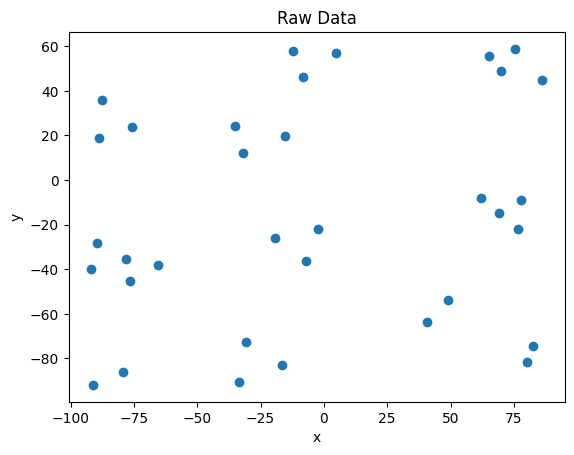

In [ ]:
import matplotlib.pyplot as plt

# 데이터 시각화
plt.scatter(data[:, 0], data[:, 1])
plt.title("Raw Data")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [ ]:
def agnes_k(data, K):
  n = len(data)
  clusters = [[i] for i in range(n)]

  while len(clusters) > K:
      min_dist = float('inf')
      pair = (None, None)

      for i in range(len(clusters)):
          for j in range(i + 1, len(clusters)):
              dist = cluster_distance(clusters[i], clusters[j], data)
              if dist < min_dist:
                  min_dist = dist
                  pair = (i, j)

      i, j = pair
      new_cluster = clusters[i] + clusters[j]

      clusters.pop(j)
      clusters.pop(i)
      clusters.append(new_cluster)

  return clusters

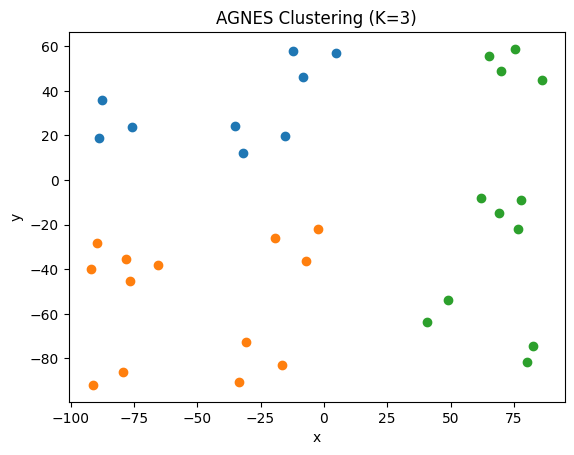

In [ ]:
clusters = agnes_k(data, K=3)  # 클러스터 개수 조절

# 색깔별로 출력
for cluster in clusters:
    points = data[cluster]
    plt.scatter(points[:, 0], points[:, 1])

plt.title("AGNES Clustering (K=3)")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

# AGNES

In [ ]:
import numpy as np

x = [
-91.1, -79.2, -88.9, -75.8, -87.4, -12.2, 4.6, -8.1, -33.4, -16.7,
-30.8, -15.5, -34.9, -31.9, 80.1, 82.7, 40.7, 48.9, 75.3, 86.1,
70.1, 65.2, 76.8, 77.9, 61.9, 69.3, -19.3, -2.5, -7, -91.9,
-89.6, -65.4, -76.6, -78.1
]

y = [
-91.9, -85.9, 19, 23.8, 36.1, 58, 56.9, 46.1, -90.8, -83,
-72.5, 19.7, 24.2, 12.3, -81.5, -74.4, -63.6, -53.6, 58.8, 45,
49.1, 55.8, -22, -8.9, -8.2, -14.9, -26.1, -22, -36.5, -39.8,
-28.3, -38.3, -45.4, -35.3
]

data = np.array(list(zip(x, y)))

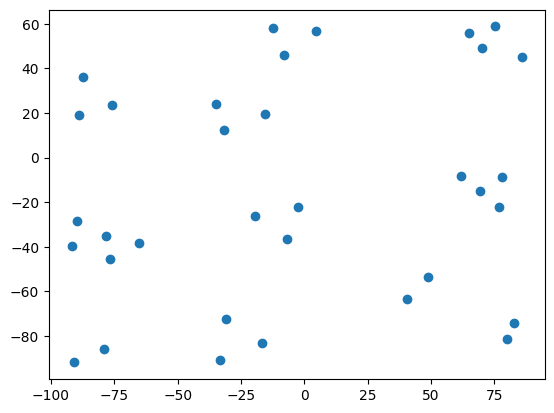

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(data[:, 0], data[:, 1])
plt.show()

In [ ]:
# 거리 함수
def distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


# 평균 거리f
def cluster_distance(c1, c2):
    dist_sum = 0
    count = 0
    for i in c1:
        for j in c2:
            dist_sum += distance(data[i], data[j])
            count += 1
    return dist_sum / count

In [ ]:
k = 3

clusters = []

for i in range(len(data)):
  clusters.append([i]) # 처음 시작 할 땐 자기 자신이 하나의 군집임

pair = (None, None)

q = len(clusters)
while q > k:
  # 가장 거리가 짧은 클러스터 찾기
  min_dist = float('inf')
  for i in range(q):
    for j in range(i+1, q):
      if i != j:
        # j는 항상 i보다 큼
        dist = cluster_distance(clusters[i], clusters[j])
        if dist < min_dist:
          min_dist = dist
          pair = (i, j)
  i, j = pair
  # 찾았으면 합치기
  # print(i, j)
  new_cluster = clusters[i]+clusters[j]
  # print(clusters)
  # print(new_cluster)
  del clusters[j]
  del clusters[i]
  clusters.append(new_cluster)
  q -= 1

In [ ]:
clusters

[[4, 2, 3, 6, 5, 7, 11, 12, 13],
 [0, 1, 29, 30, 31, 32, 33, 26, 27, 28, 8, 9, 10],
 [19, 18, 20, 21, 24, 25, 22, 23, 14, 15, 16, 17]]

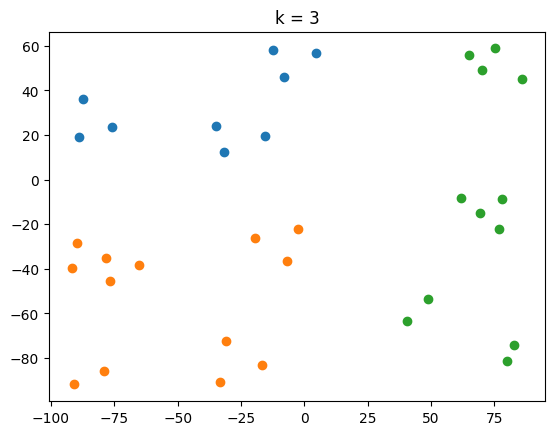

In [ ]:
for cluster in clusters:
  plt.scatter(data[cluster][:, 0], data[cluster][:, 1])
plt.title(f"k = {k}")
plt.show()

**병합과정 시각화하기**

In [ ]:
def AGNES(k = 3):
  clusters = []

  for i in range(len(data)):
    clusters.append([i]) # 처음 시작 할 땐 자기 자신이 하나의 군집임

  pair = (None, None)

  q = len(clusters)
  while q > k:
    # 가장 거리가 짧은 클러스터 찾기
    min_dist = float('inf')
    for i in range(q):
      for j in range(i+1, q):
        if i != j:
          # j는 항상 i보다 큼
          dist = cluster_distance(clusters[i], clusters[j])
          if dist < min_dist:
            min_dist = dist
            pair = (i, j)
    i, j = pair
    # 찾았으면 합치기
    # print(i, j)
    new_cluster = clusters[i]+clusters[j]
    # print(clusters)
    # print(new_cluster)
    del clusters[j]
    del clusters[i]
    clusters.append(new_cluster)
    q -= 1

  return clusters
  # clusters 안에는 데이터들의 인덱스가 들어가있음

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation

In [ ]:
def update():
  agnes = AGNES(i)
  for cluster in agnes:
    plt.scatter(data[cluster][:, 0], data[cluster][:, 1])
  plt.show()

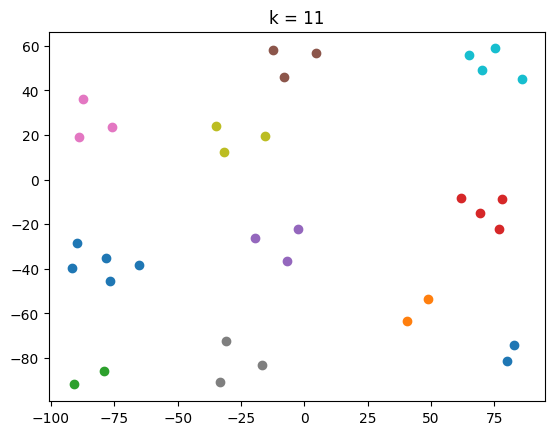

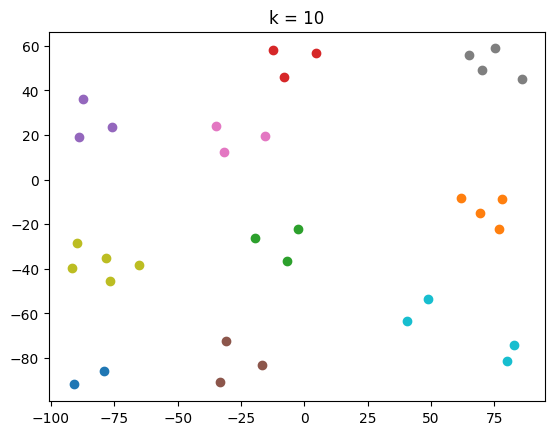

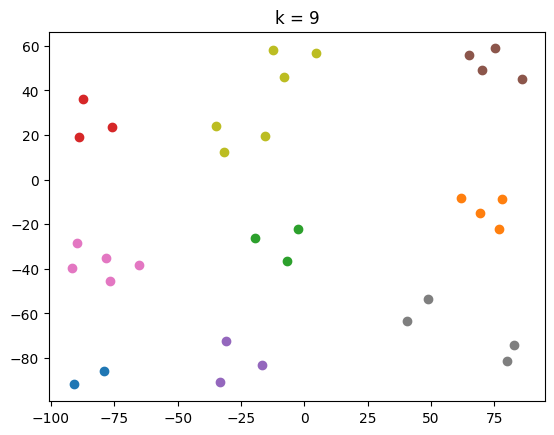

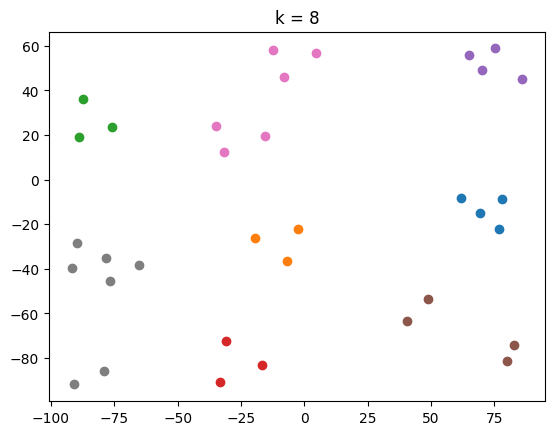

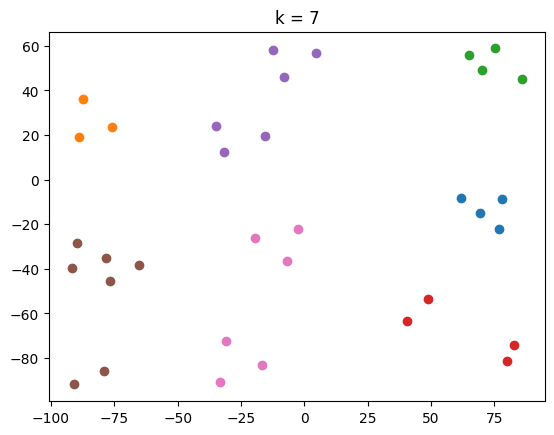

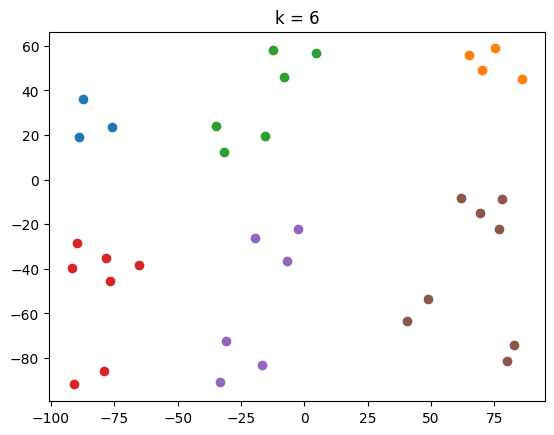

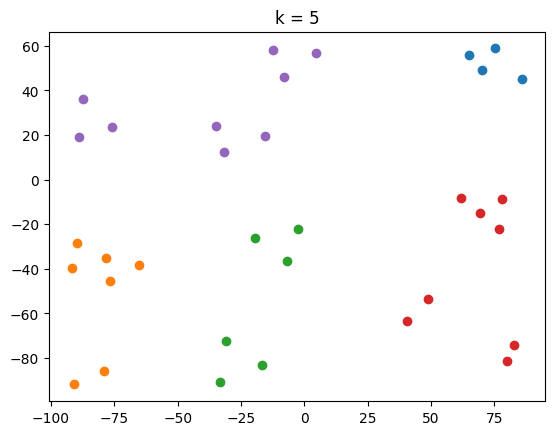

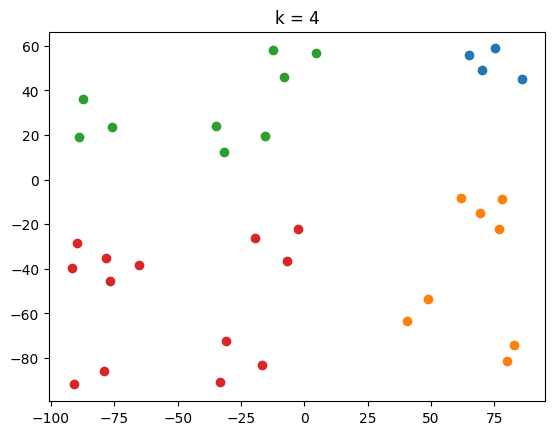

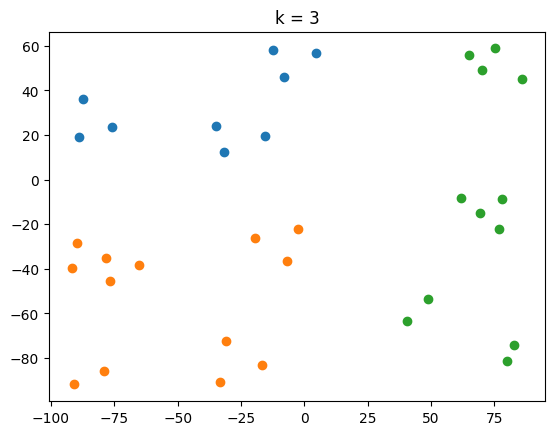

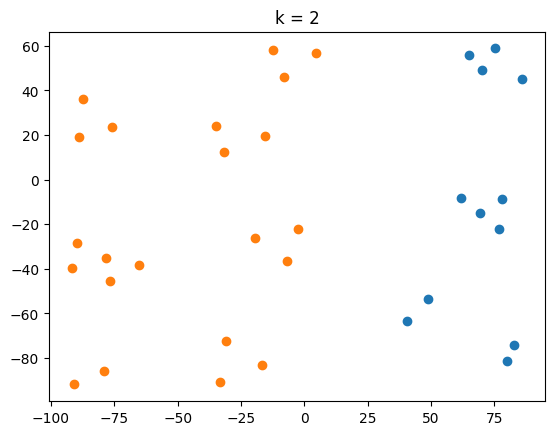

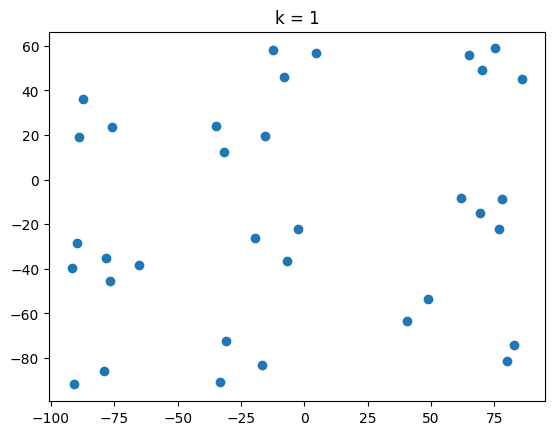

In [ ]:
for i in range(11, 0, -1):
  agnes = AGNES(i)
  for cluster in agnes:
    plt.scatter(data[cluster][:, 0], data[cluster][:, 1])
  plt.title(f"k = {i}")
  plt.show()